#**Details:**
**Name:** Siddhesh Abasaheb Mane

**PRN:** 202401040187

**Batch:** A2

**Roll No.:** 46



### Objective
To implement clustering algorithms on a real-world dataset, identify meaningful groups in the observations, and evaluate clustering quality using Silhouette Score, Davies-Bouldin Index, and visual inspection.

**Selected application:** Iris flower grouping using unsupervised clustering.

**Dataset:** Iris dataset built into Scikit-learn. It contains 150 flower samples and four numerical measurements. No missing-value imputation or categorical encoding is required. Standardisation is applied because distance-based clustering algorithms are sensitive to feature scales.

## 1. Introduction

Clustering is an **unsupervised machine-learning technique** used to group similar observations together without using predefined target labels during model training.

The goal is to:
- Place similar observations in the same cluster.
- Place dissimilar observations in different clusters.
- Discover patterns or natural groupings in data.

This practical uses the Iris dataset, which contains sepal length, sepal width, petal length and petal width measurements. Three clustering algorithms are implemented:

1. **K-Means Clustering:** Divides observations into a specified number of clusters by minimising within-cluster distances.
2. **Agglomerative Hierarchical Clustering:** Builds clusters by repeatedly merging the closest groups.
3. **DBSCAN:** Groups dense regions of observations and identifies isolated observations as noise.

The original Iris species labels are kept only for optional external comparison after clustering. They are not supplied to the clustering algorithms.

## 2. Import Required Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("All libraries imported successfully.")

All libraries imported successfully.


## 3. Dataset Selection

The **Iris dataset** is selected for this clustering practical. It is a classic dataset available directly through Scikit-learn.

Dataset characteristics:
- 150 flower samples.
- Four numerical input features.
- Three known species: Setosa, Versicolor and Virginica.
- No missing values in the built-in dataset.
- Suitable for exploring unsupervised grouping.

### Input features
1. Sepal length (cm)
2. Sepal width (cm)
3. Petal length (cm)
4. Petal width (cm)

The species labels are available as reference information. Clustering is performed only on the four measurements, without using the species labels.

**Source:** Scikit-learn Iris dataset: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html

In [ ]:
# Load Iris dataset

iris = load_iris(as_frame=True)

X = iris.data.copy()
true_labels = iris.target.copy()

df = X.copy()
df["species"] = true_labels.map(dict(enumerate(iris.target_names)))

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

display(df.head())

Dataset loaded successfully.
Dataset shape: (150, 5)
Number of samples: 150
Number of features: 4


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
# Inspect feature names and data types

print("Feature names:")
print(X.columns.tolist())

print("\\nData types:")
print(X.dtypes)

print("\\nDataset information:")
X.info()

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
\nData types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


Species counts:


,count
species,
setosa,50
versicolor,50
virginica,50


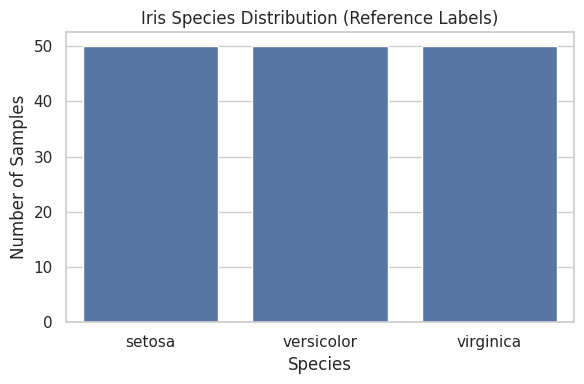

In [ ]:
# Check species distribution for later interpretation

species_counts = df["species"].value_counts()

print("Species counts:")
display(species_counts)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="species", order=iris.target_names)
plt.title("Iris Species Distribution (Reference Labels)")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

In [ ]:
# Statistical summary of numerical features

display(X.describe().T)

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


In [ ]:
# Verify missing values and duplicate rows

missing_summary = pd.DataFrame({
    "Missing Count": X.isnull().sum(),
    "Missing Percentage": (X.isnull().mean() * 100).round(2)
})

display(missing_summary)

print("Total missing feature values:", X.isnull().sum().sum())
print("Duplicate feature rows:", X.duplicated().sum())

,Missing Count,Missing Percentage
sepal length (cm),0,0.0
sepal width (cm),0,0.0
petal length (cm),0,0.0
petal width (cm),0,0.0


Total missing feature values: 0
Duplicate feature rows: 1


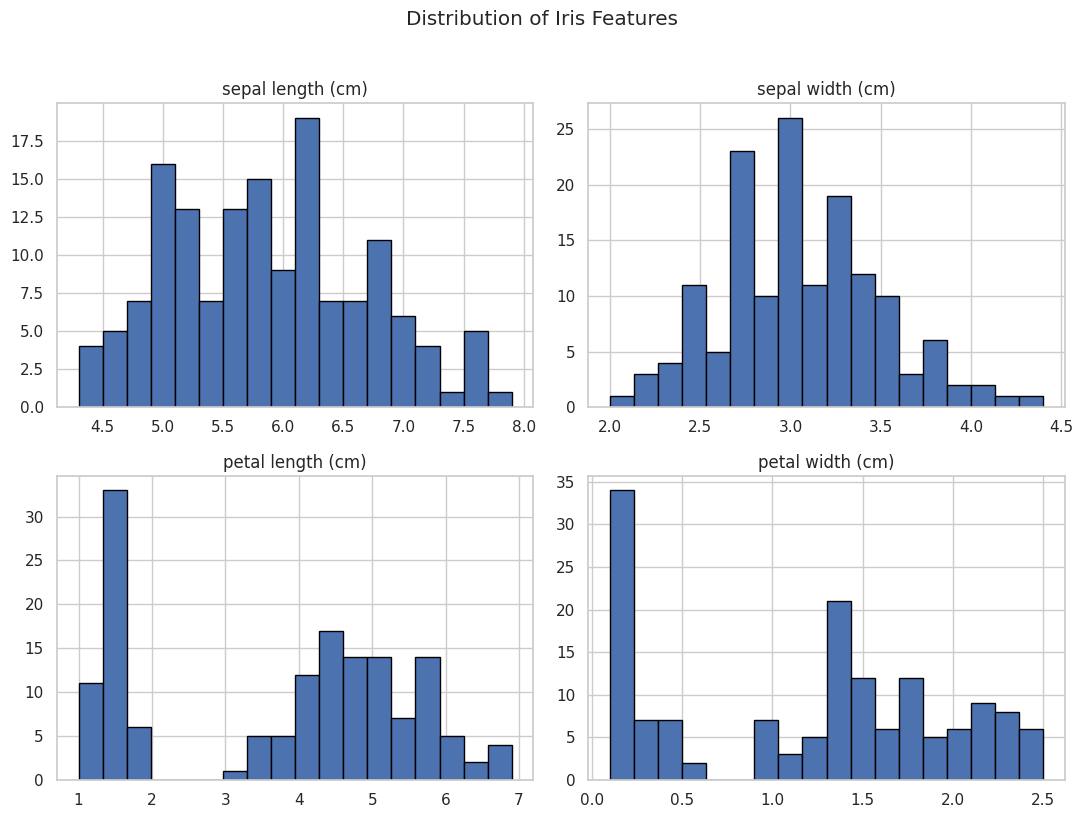

In [ ]:
# Visualise feature distributions

X.hist(figsize=(11, 8), bins=18, edgecolor="black")
plt.suptitle("Distribution of Iris Features", y=1.02)
plt.tight_layout()
plt.show()

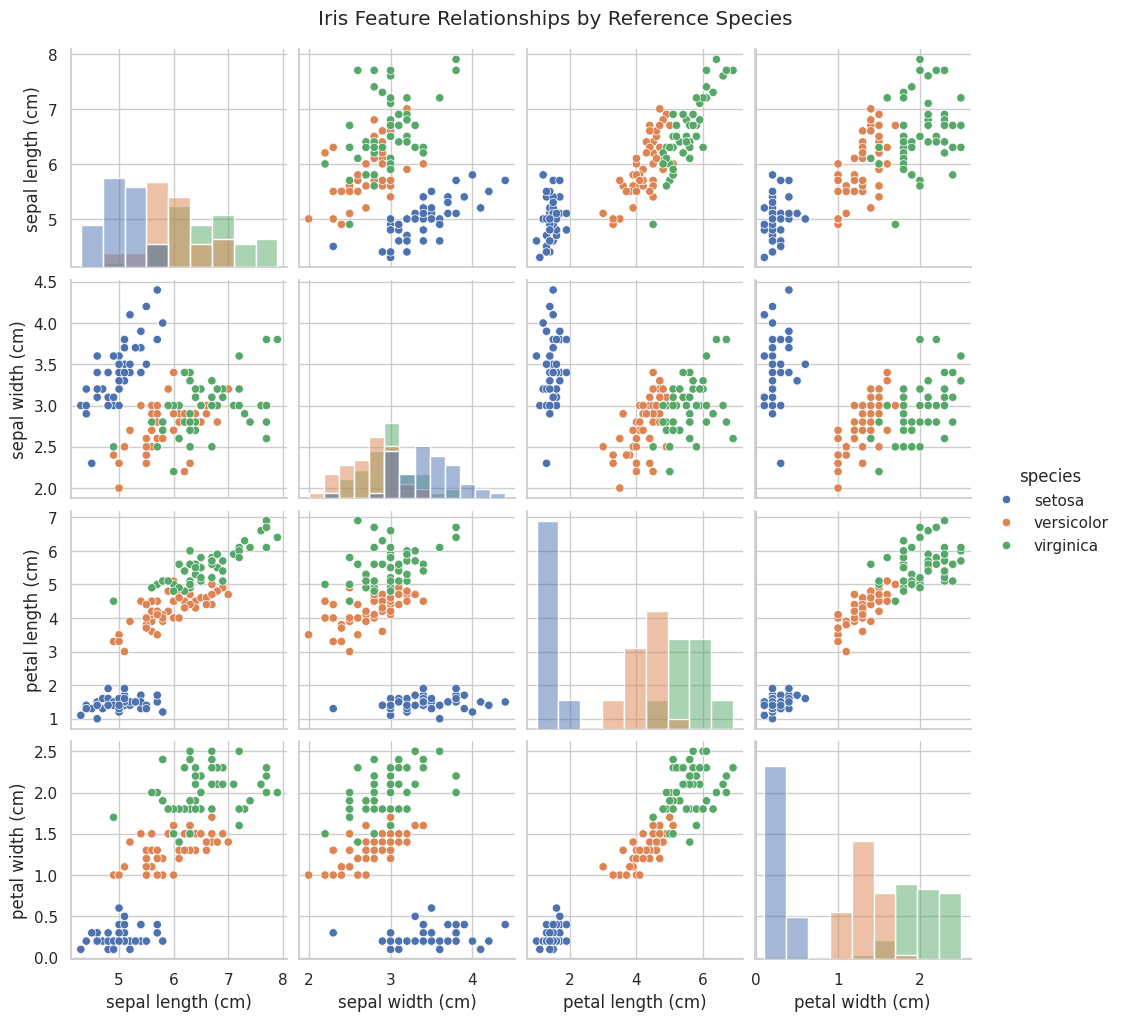

In [ ]:
# Pair plot to inspect possible group separation

plot_df = X.copy()
plot_df["species"] = df["species"]

sns.pairplot(plot_df, hue="species", diag_kind="hist")
plt.suptitle("Iris Feature Relationships by Reference Species", y=1.02)
plt.show()

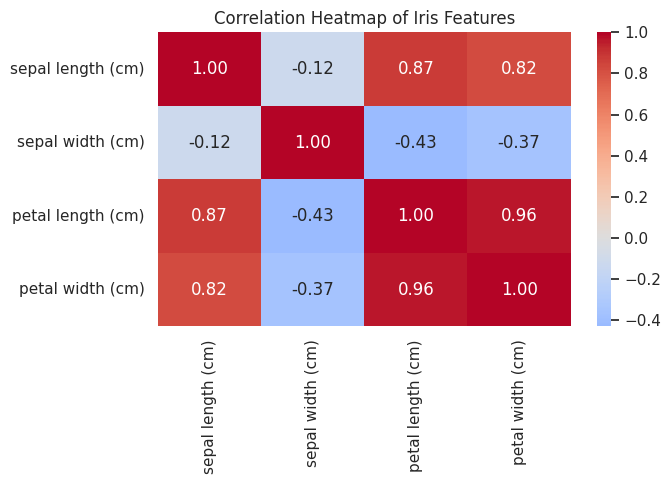

In [ ]:
# Correlation heatmap

plt.figure(figsize=(7, 5))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap of Iris Features")
plt.tight_layout()
plt.show()

## 4. Data Preparation and Feature Scaling

The Iris dataset already contains numerical input features and has no missing values. Therefore, missing-value imputation and categorical encoding are not required.

However, the features have different numerical ranges. Clustering algorithms such as K-Means and DBSCAN use distances, so features with larger scales can dominate distance calculations.

**Standardisation** transforms each feature to have approximately zero mean and unit standard deviation. The scaler is fitted to the dataset and the transformed values are used for clustering.

The species labels are not used as input to any clustering algorithm.

In [ ]:
# Standardise numerical features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

print("Original feature values:")
display(X.head())

print("Standardised feature values:")
display(X_scaled_df.head())

print("Scaled feature means (approximately 0):")
print(X_scaled_df.mean().round(3))

print("\\nScaled feature standard deviations (approximately 1):")
print(X_scaled_df.std(ddof=0).round(3))

Original feature values:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Standardised feature values:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


Scaled feature means (approximately 0):
sepal length (cm)   -0.0
sepal width (cm)    -0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64
\nScaled feature standard deviations (approximately 1):
sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64


## 5. K-Means Clustering

K-Means is a centroid-based clustering algorithm. It divides the dataset into **K clusters**.

### Working
1. Choose the number of clusters K.
2. Initialise K centroids.
3. Assign each observation to its nearest centroid.
4. Recalculate each centroid as the mean of observations assigned to it.
5. Repeat assignment and centroid updates until the assignments stabilise or the iteration limit is reached.

K-Means attempts to minimise the within-cluster sum of squared distances, called **inertia**.

The elbow method and silhouette score are used to help examine different values of K.

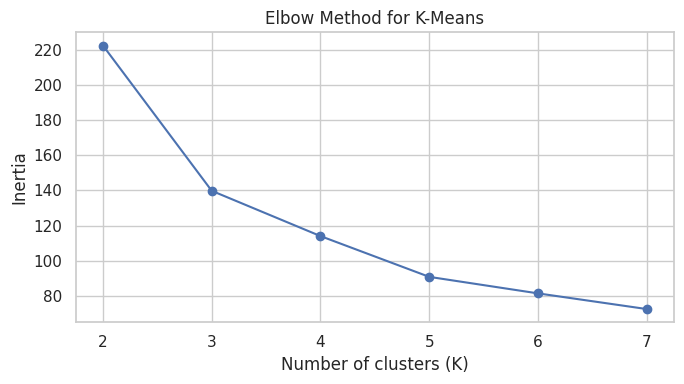

In [ ]:
# Elbow method: calculate inertia for different K values

inertia_values = []
k_values = range(2, 8)

for k in k_values:
    kmeans_temp = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    kmeans_temp.fit(X_scaled)
    inertia_values.append(kmeans_temp.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

In [ ]:
# Compare Silhouette Score for different K values

k_silhouette = []

for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    k_silhouette.append({"K": k, "Silhouette Score": score})

k_silhouette_df = pd.DataFrame(k_silhouette)
display(k_silhouette_df.round(4))

best_k = int(
    k_silhouette_df.loc[
        k_silhouette_df["Silhouette Score"].idxmax(), "K"
    ]
)
print("K selected by highest silhouette score:", best_k)

,K,Silhouette Score
0,2,0.5818
1,3,0.4599
2,4,0.3869
3,5,0.3459
4,6,0.3171
5,7,0.3202


K selected by highest silhouette score: 2


In [ ]:
# Train final K-Means using the selected K

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

print("K-Means clustering completed.")
print("Cluster counts:")
display(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means clustering completed.
Cluster counts:


,count
0,100
1,50


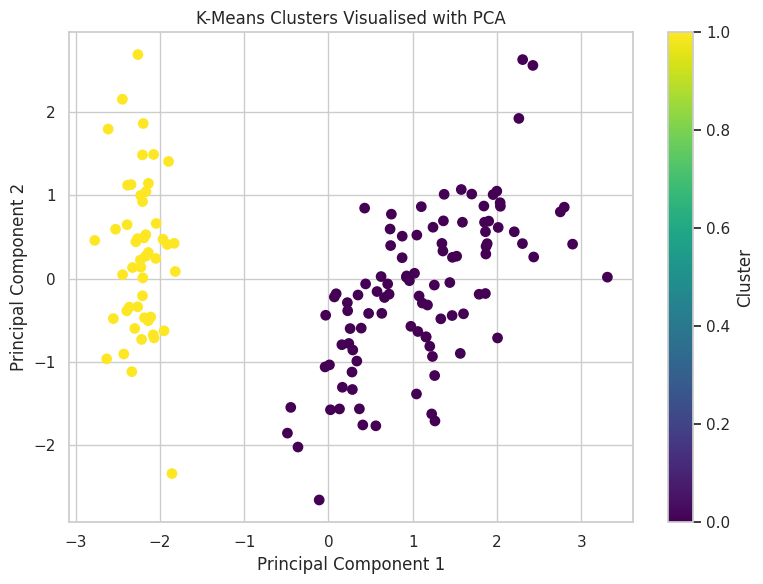

Variance retained by 2 PCA components: 0.9581


In [ ]:
# Visualise K-Means clusters using PCA in two dimensions

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=45
)
plt.title("K-Means Clusters Visualised with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print("Variance retained by 2 PCA components:",
      round(pca.explained_variance_ratio_.sum(), 4))

## 6. Agglomerative Hierarchical Clustering

Agglomerative Clustering is a bottom-up hierarchical clustering algorithm.

### Working
1. Initially, every observation is treated as an individual cluster.
2. Calculate distances between clusters.
3. Merge the two closest clusters.
4. Repeat until the requested number of clusters remains.

The **Ward linkage** method merges clusters in a way that minimises the increase in within-cluster variance.

Unlike K-Means, Agglomerative Clustering does not calculate cluster centroids iteratively. It constructs a hierarchy of merges and stops at the requested number of clusters.

In [ ]:
# Compare Agglomerative Clustering for different cluster counts

agglo_rows = []

for k in range(2, 8):
    agglo_temp = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    labels = agglo_temp.fit_predict(X_scaled)

    agglo_rows.append({
        "Number of Clusters": k,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels)
    })

agglo_comparison = pd.DataFrame(agglo_rows)
display(agglo_comparison.round(4))

,Number of Clusters,Silhouette Score,Davies-Bouldin Index
0,2,0.5770,0.5917
1,3,0.4467,0.8035
2,4,0.4006,0.9788
3,5,0.3306,0.9742
4,6,0.3149,0.9895
5,7,0.3170,0.9706


In [ ]:
# Select the cluster count with the highest silhouette score

best_agglo_k = int(
    agglo_comparison.loc[
        agglo_comparison["Silhouette Score"].idxmax(),
        "Number of Clusters"
    ]
)

print("Selected Agglomerative cluster count:", best_agglo_k)

Selected Agglomerative cluster count: 2


In [ ]:
# Train final Agglomerative Clustering model

agglo_model = AgglomerativeClustering(
    n_clusters=best_agglo_k,
    linkage="ward"
)

agglo_labels = agglo_model.fit_predict(X_scaled)

print("Agglomerative clustering completed.")
print("Cluster counts:")
display(pd.Series(agglo_labels).value_counts().sort_index())

Agglomerative clustering completed.
Cluster counts:


,count
0,101
1,49


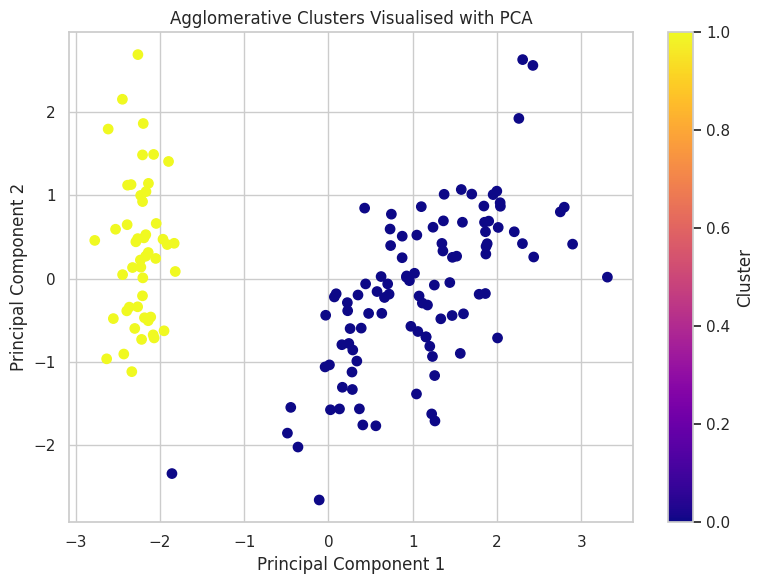

In [ ]:
# Visualise Agglomerative clusters using PCA

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=agglo_labels,
    cmap="plasma",
    s=45
)
plt.title("Agglomerative Clusters Visualised with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

## 7. DBSCAN Clustering

DBSCAN stands for **Density-Based Spatial Clustering of Applications with Noise**.

Unlike K-Means and Agglomerative Clustering, DBSCAN does not require the number of clusters to be specified in advance. It groups observations in dense regions and identifies observations in sparse regions as noise.

### Important parameters
- **eps:** Maximum neighbourhood distance between two observations for them to be considered neighbours.
- **min_samples:** Minimum number of observations required in an eps-neighbourhood for a point to be considered a core point.

### DBSCAN point types
- **Core point:** Has at least `min_samples` observations within its eps-neighbourhood.
- **Border point:** Is close to a core point but does not itself have enough neighbours to be a core point.
- **Noise point:** Does not belong to a dense cluster. Scikit-learn labels noise points as `-1`.

The values of eps and min_samples affect the number of clusters and noise points. A small parameter search is used to inspect candidate settings.

In [ ]:
# Search selected DBSCAN parameter combinations

dbscan_rows = []
best_dbscan_score = -1
best_dbscan_params = None
best_dbscan_labels = None

eps_values = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
min_samples_values = [3, 4, 5]

for eps in eps_values:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_scaled)

        non_noise_mask = labels != -1
        valid_labels = labels[non_noise_mask]
        number_clusters = len(set(valid_labels))
        noise_count = int((labels == -1).sum())

        # Silhouette and DB index require at least 2 clusters
        # and fewer clusters than observations.
        if 2 <= number_clusters < len(valid_labels):
            sil = silhouette_score(
                X_scaled[non_noise_mask],
                valid_labels
            )
            dbi = davies_bouldin_score(
                X_scaled[non_noise_mask],
                valid_labels
            )
        else:
            sil = np.nan
            dbi = np.nan

        dbscan_rows.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clusters (excluding noise)": number_clusters,
            "Noise Points": noise_count,
            "Silhouette Score": sil,
            "Davies-Bouldin Index": dbi
        })

        if pd.notna(sil) and sil > best_dbscan_score:
            best_dbscan_score = sil
            best_dbscan_params = {
                "eps": eps,
                "min_samples": min_samples
            }
            best_dbscan_labels = labels.copy()

dbscan_search_df = pd.DataFrame(dbscan_rows)
display(dbscan_search_df.round(4))

print("Best DBSCAN parameters by non-noise silhouette score:",
      best_dbscan_params)

,eps,min_samples,Clusters (excluding noise),Noise Points,Silhouette Score,Davies-Bouldin Index
0,0.3,3,10,84,0.3974,0.7060
1,0.3,4,5,107,0.4561,0.7023
2,0.3,5,3,120,0.6302,0.4594
3,0.4,3,10,39,0.4184,0.7664
4,0.4,4,5,61,0.5015,0.7774
5,0.4,5,6,66,0.4865,0.7855
6,0.5,3,7,17,0.2591,0.7056
7,0.5,4,2,33,0.6550,0.4951
8,0.5,5,2,34,0.6559,0.4942
9,0.6,3,4,9,0.3452,0.6651


Best DBSCAN parameters by non-noise silhouette score: {'eps': 0.5, 'min_samples': 5}


In [ ]:
# Fit final DBSCAN model using selected parameters

if best_dbscan_params is None:
    print("No tested DBSCAN setting produced at least two non-noise clusters.")
    dbscan_labels = DBSCAN(eps=0.5, min_samples=5).fit_predict(X_scaled)
else:
    dbscan_model = DBSCAN(**best_dbscan_params)
    dbscan_labels = dbscan_model.fit_predict(X_scaled)

print("DBSCAN completed.")
print("Cluster/noise label counts:")
display(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN completed.
Cluster/noise label counts:


,count
-1,34
0,45
1,71


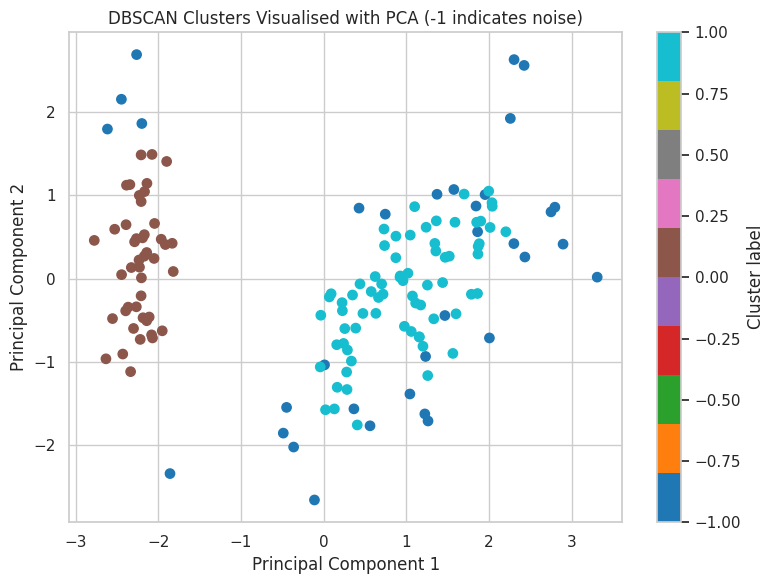

In [ ]:
# Visualise DBSCAN clusters using PCA

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap="tab10",
    s=45
)
plt.title("DBSCAN Clusters Visualised with PCA (-1 indicates noise)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster label")
plt.tight_layout()
plt.show()

## 8. Clustering Evaluation Metrics

Clustering is an unsupervised task, so the model does not receive correct cluster labels during training. Internal clustering metrics assess how well the resulting groups are separated and how compact they are.

### 1. Silhouette Score
The silhouette score measures how similar an observation is to its own cluster compared with other clusters.

\[
s = \frac{b-a}{\max(a,b)}
\]

- `a`: average distance to observations in the same cluster.
- `b`: lowest average distance to observations in another cluster.

Range: -1 to +1. Higher values generally indicate better-separated clusters.

### 2. Davies-Bouldin Index
The Davies-Bouldin Index measures similarity between clusters, considering within-cluster spread and separation between cluster centres. Lower values generally indicate better clustering.

### 3. Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI)
The dataset provides known species labels. These labels were not used for clustering. ARI and NMI can be calculated **after clustering** to compare the discovered grouping with the known species labels. Higher values generally indicate closer agreement.

### DBSCAN evaluation note
For DBSCAN, silhouette and Davies-Bouldin scores below are calculated on non-noise points only. The number of noise points is reported separately. This avoids treating all noise observations as one ordinary cluster.

In [ ]:
# Helper function to calculate valid internal clustering metrics

def internal_cluster_metrics(data, labels, ignore_noise=False):
    labels = np.asarray(labels)

    if ignore_noise:
        mask = labels != -1
        data_eval = np.asarray(data)[mask]
        labels_eval = labels[mask]
    else:
        data_eval = np.asarray(data)
        labels_eval = labels

    unique_clusters = np.unique(labels_eval)

    if len(unique_clusters) < 2 or len(unique_clusters) >= len(labels_eval):
        return np.nan, np.nan

    sil = silhouette_score(data_eval, labels_eval)
    dbi = davies_bouldin_score(data_eval, labels_eval)
    return sil, dbi

In [ ]:
# Compare all three clustering algorithms

clustering_results = []

models_labels = {
    "K-Means": kmeans_labels,
    "Agglomerative": agglo_labels,
    "DBSCAN": dbscan_labels
}

for model_name, labels in models_labels.items():
    ignore_noise = model_name == "DBSCAN"

    silhouette, db_index = internal_cluster_metrics(
        X_scaled,
        labels,
        ignore_noise=ignore_noise
    )

    clustering_results.append({
        "Algorithm": model_name,
        "Number of Clusters": len(set(labels) - ({-1} if ignore_noise else set())),
        "Noise Points": int(np.sum(np.asarray(labels) == -1)) if ignore_noise else 0,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index,
        "Adjusted Rand Index": adjusted_rand_score(true_labels, labels),
        "Normalized Mutual Information": normalized_mutual_info_score(true_labels, labels)
    })

clustering_results_df = pd.DataFrame(clustering_results).set_index("Algorithm")
display(clustering_results_df.round(4))

,Number of Clusters,Noise Points,Silhouette Score,Davies-Bouldin Index,Adjusted Rand Index,Normalized Mutual Information
Algorithm,,,,,,
K-Means,2,0,0.5818,0.5933,0.5681,0.7337
Agglomerative,2,0,0.5770,0.5917,0.5438,0.6925
DBSCAN,2,34,0.6559,0.4942,0.4421,0.5114


In [ ]:
# Display best algorithm for each internal clustering metric

valid_silhouette = clustering_results_df.dropna(subset=["Silhouette Score"])
valid_dbi = clustering_results_df.dropna(subset=["Davies-Bouldin Index"])

print("Highest Silhouette Score:",
      valid_silhouette["Silhouette Score"].idxmax())

print("Lowest Davies-Bouldin Index:",
      valid_dbi["Davies-Bouldin Index"].idxmin())

print("\\nExternal comparison only (species labels not used for fitting):")
print("Highest Adjusted Rand Index:",
      clustering_results_df["Adjusted Rand Index"].idxmax())
print("Highest Normalized Mutual Information:",
      clustering_results_df["Normalized Mutual Information"].idxmax())

Highest Silhouette Score: DBSCAN
Lowest Davies-Bouldin Index: DBSCAN
\nExternal comparison only (species labels not used for fitting):
Highest Adjusted Rand Index: K-Means
Highest Normalized Mutual Information: K-Means


## 9. Visual Comparison with the Known Species Labels

The known species labels were not supplied to any clustering algorithm. They can be displayed after clustering as a reference to understand how discovered groups relate to the original species.

Cluster numbers themselves have no biological meaning. For example, cluster `0` does not automatically correspond to Setosa. The mapping between cluster IDs and species is arbitrary.

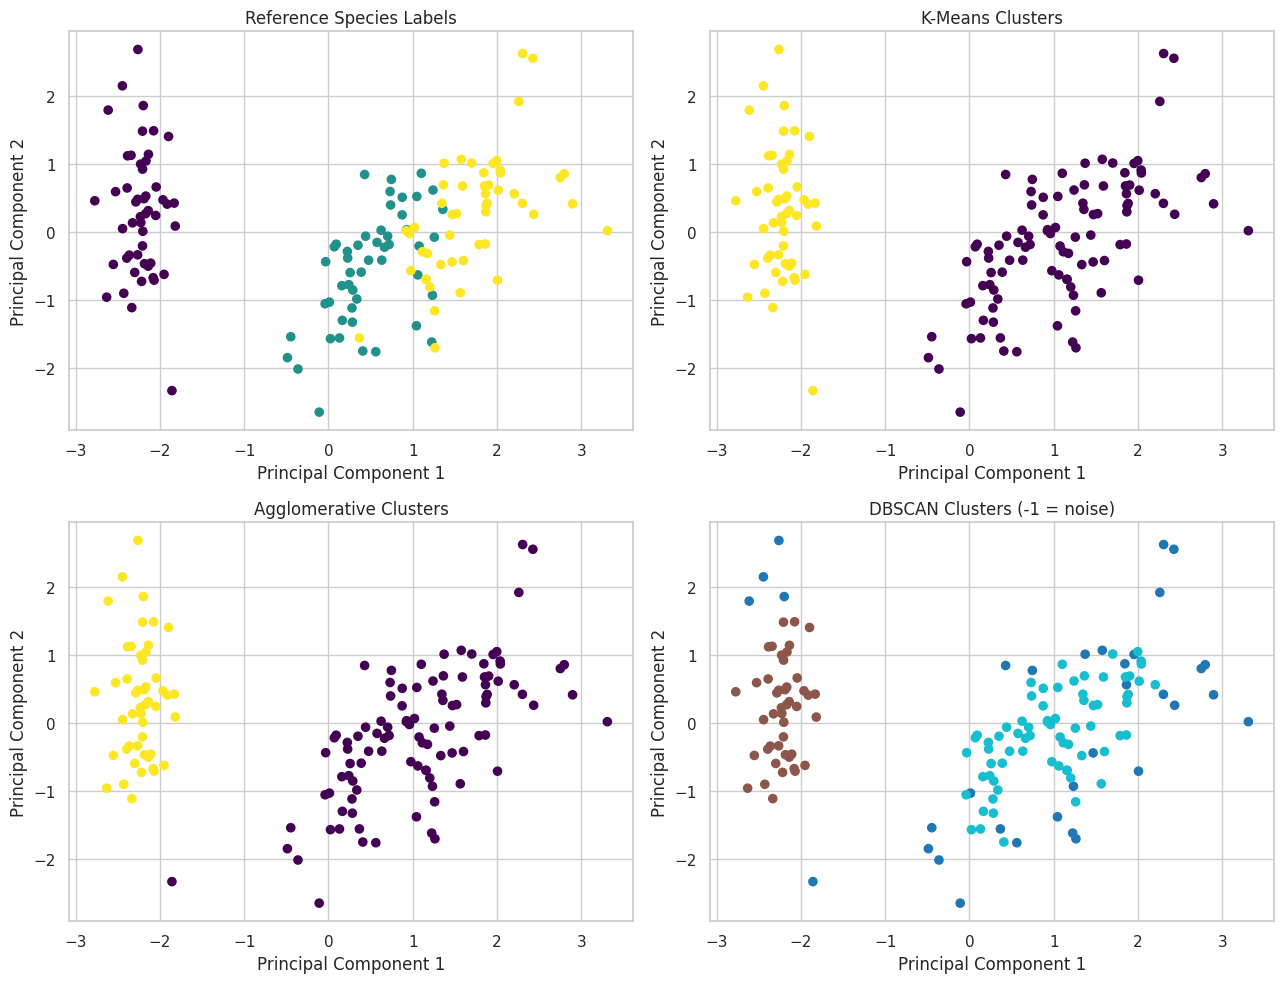

In [ ]:
# PCA visualisation of reference species and predicted clusters

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=true_labels, cmap="viridis", s=35)
axes[0, 0].set_title("Reference Species Labels")

axes[0, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="viridis", s=35)
axes[0, 1].set_title("K-Means Clusters")

axes[1, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=agglo_labels, cmap="viridis", s=35)
axes[1, 0].set_title("Agglomerative Clusters")

axes[1, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap="tab10", s=35)
axes[1, 1].set_title("DBSCAN Clusters (-1 = noise)")

for ax in axes.ravel():
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

In [ ]:
# Cross-tabulate clusters against reference species for interpretation only

for model_name, labels in models_labels.items():
    print("\\n", model_name, "cluster composition:")
    cluster_table = pd.crosstab(
        pd.Series(labels, name="Cluster"),
        pd.Series(iris.target_names[true_labels], name="Reference Species")
    )
    display(cluster_table)

\n K-Means cluster composition:


Reference Species,setosa,versicolor,virginica
Cluster,,,
0,0,50,50
1,50,0,0


\n Agglomerative cluster composition:


Reference Species,setosa,versicolor,virginica
Cluster,,,
0,1,50,50
1,49,0,0


\n DBSCAN cluster composition:


Reference Species,setosa,versicolor,virginica
Cluster,,,
-1,5,11,18
0,45,0,0
1,0,39,32


## 10. Critical Analysis of Results

### Comparison of Results

| Evaluation Metric | K-Means | Agglomerative | DBSCAN |
| :--- | :---: | :---: | :---: |
| **Number of clusters** | 2 | 2 | 2 |
| **Noise points** | 0 | 0 | 34 |
| **Silhouette Score** | 0.5818 | 0.5770 | 0.6559 |
| **Davies-Bouldin Index** | 0.5933 | 0.5917 | 0.4942 |
| **Adjusted Rand Index** | 0.5681 | 0.5438 | 0.4421 |
| **Normalized Mutual Information** | 0.7337 | 0.6925 | 0.5114 |

<br>

1. K-Means Clustering: K-Means selected two clusters based on the highest Silhouette Score among the tested values of K. It achieved a Silhouette Score of 0.5818 and an ARI of 0.5681. Its NMI score of 0.7337 was the highest among the three algorithms, indicating the strongest agreement with the original species labels. The clusters separated all 50 Setosa samples from the combined Versicolor and Virginica samples.

2. Agglomerative Clustering: Agglomerative Clustering also selected two clusters and achieved a Silhouette Score of 0.5770. Its Davies-Bouldin Index was 0.5917, slightly lower than K-Means. Its ARI and NMI were marginally lower than those of K-Means. The cluster composition showed that one Setosa sample was grouped with the Versicolor and Virginica samples, while the remaining 49 Setosa samples formed the other cluster.

3. DBSCAN Clustering: DBSCAN achieved the highest Silhouette Score of 0.6559 and the lowest Davies-Bouldin Index of 0.4942. However, it classified 34 observations as noise. Its ARI of 0.4421 and NMI of 0.5114 were lower than those of K-Means and Agglomerative Clustering. This indicates that although DBSCAN formed compact groups among the observations it retained, its overall grouping had less agreement with the original species labels.

4. Effect of DBSCAN Parameters: The selected DBSCAN parameters were eps = 0.5 and min_samples = 5. These parameters produced two clusters and 34 noise points. The results demonstrate that DBSCAN is sensitive to the choice of parameters, which affects the number of clusters and the number of observations classified as noise.

5. Visualisation: PCA reduced the four original features to two principal components while retaining approximately 95.81% of the variance. The visualisations show a clear separation of Setosa from the other two species, while Versicolor and Virginica have overlapping feature patterns.

6. Overall Interpretation: K-Means provided the strongest agreement with the original species labels, while DBSCAN produced the best internal clustering scores. However, DBSCAN's internal metrics were calculated only on its non-noise observations, whereas the K-Means and Agglomerative metrics used all observations. Therefore, their Silhouette and Davies-Bouldin scores should not be interpreted as a perfectly equal comparison.


## 11. Strengths and Limitations of Clustering Algorithms

### K-Means
**Strengths**
- Simple and computationally efficient.
- Works well when clusters are relatively compact and separated.
- Easy to interpret using cluster centroids.

**Limitations**
- Requires the number of clusters in advance.
- Sensitive to initial centroid placement and outliers.
- Works less well for clusters with irregular shapes or very different densities.

### Agglomerative Hierarchical Clustering
**Strengths**
- Builds a hierarchy of groups.
- Does not require random centroid initialisation.
- Supports different linkage strategies.

**Limitations**
- Requires the final number of clusters to be chosen for flat cluster labels.
- Can be computationally expensive for large datasets.
- Results depend on the linkage method and distance measure.

### DBSCAN
**Strengths**
- Does not require the number of clusters in advance.
- Can find non-spherical dense clusters.
- Identifies noise and isolated observations.

**Limitations**
- Sensitive to `eps` and `min_samples`.
- Can struggle when clusters have very different densities.
- May label many observations as noise if parameters are unsuitable.

## 12. Suitability and Applications

| Algorithm | Suitable Situations | Main Advantage | Main Concern |
|---|---|---|---|
| **K-Means** | Compact groups with broadly similar size and density | Efficient and straightforward | Must choose K; sensitive to outliers |
| **Agglomerative** | Hierarchical group structures and smaller datasets | Reveals nested relationships | Can be costly on large datasets |
| **DBSCAN** | Dense groups with noise and irregular shapes | Finds noise without predefining cluster count | Parameter and density sensitivity |

Clustering can be used for customer segmentation, document grouping, image segmentation, pattern discovery, and exploratory biological data analysis. In this practical, the goal is to explore whether the numerical flower measurements form groups that relate to the known Iris species.

## 13. Future Scope and Improvements

1. **Parameter Optimisation:** Explore a wider range of K values, DBSCAN `eps` and `min_samples`, and different linkage choices for Agglomerative Clustering.
2. **Alternative Algorithms:** Compare Gaussian Mixture Models, Mean Shift, Spectral Clustering and OPTICS.
3. **Dimensionality Reduction:** Study PCA and other dimensionality-reduction methods before clustering, while checking whether important information is retained.
4. **Robustness Analysis:** Repeat clustering with different random seeds and sample subsets to examine stability.
5. **Feature Selection:** Investigate whether a smaller set of measurements produces more interpretable clusters.
6. **External Validation:** Compare clustering with independently known labels only after fitting, using metrics such as ARI and NMI.
7. **Real-World Datasets:** Apply the same workflow to larger customer, transaction, or biological datasets where group structure is not already known.

The Iris dataset is small and well studied. Future work should test the algorithms on larger and more complex datasets to assess how well the findings generalise.

## 14. Conclusion

In this practical, three unsupervised clustering algorithms — K-Means, Agglomerative Hierarchical Clustering and DBSCAN — were successfully implemented on the Iris dataset. The dataset contained 150 flower observations with four numerical features: sepal length, sepal width, petal length and petal width. Standardisation was performed to ensure that features with larger numerical ranges did not dominate distance calculations.

The optimal number of clusters for K-Means and Agglomerative Clustering was found to be two using the Silhouette Score. DBSCAN identified two clusters and classified 34 observations as noise using eps = 0.5 and min_samples = 5.

Among the tested algorithms, K-Means achieved the highest agreement with the original species labels, with an ARI of 0.5681 and an NMI of 0.7337. DBSCAN achieved the highest Silhouette Score of 0.6559 and the lowest Davies-Bouldin Index of 0.4942, although it excluded 34 observations from its internal metric calculations as noise.

The practical demonstrated that different clustering algorithms identify groups using different approaches. K-Means is suitable for compact, well-separated clusters, Agglomerative Clustering is useful for understanding hierarchical relationships, and DBSCAN is useful for discovering dense regions and identifying noise without specifying the number of clusters in advance.

Thus, the experiment successfully demonstrated unsupervised learning, cluster evaluation, parameter selection and visual interpretation of discovered patterns. It also showed that the choice of a clustering algorithm should depend on the dataset structure and the objective of the analysis.